# Machine Learning 1 — Homework 1, Question 4

Predict **Average Localization Error (`ale`)** from the four specified predictors and assess the distribution of the signed **held-out test residuals** using normal probability plots and `scipy.stats.normaltest`.

## Data source and scope

The data are from [UCI dataset 844: Average Localization Error (ALE) in sensor node localization process in WSNs](https://archive.ics.uci.edu/dataset/844/average+localization+error+(ale)+in+sensor+node+localization+process+in+wsns). The official CSV is `mcs_ds_edited_iter_shuffled.csv`. UCI reports **107 samples**, four predictors, the target `ale`, and the additional column `sd_ale`, with no missing values. The target is measured in meters, according to the UCI variable table.

- Predictors: `anchor_ratio`, `trans_range`, `node_density`, `iterations`.
- Target: `ale` only. `sd_ale` and any CSV index columns are excluded from the model inputs.
- One shared split: `train_test_split(test_size=0.2, random_state=42)`, without stratification.
- Models: linear regression, scaled RBF SVR, and the specified depth-limited decision tree.
- The split, seed, model count, and fixed model settings are **implementation choices for this experiment**, not additional requirements imposed by the homework. They are baseline settings, not claimed to be optimal. No tuning is performed using the test errors or normality p-values.
- SVR scaling is fitted only on the training data inside a pipeline. The target is not transformed, so predictions and residuals retain the original `ale` units. Each model uses its native scikit-learn training method.

This notebook covers **Q4 only**.

**Reproduction:** keep this notebook together with its `data/` folder and run all cells from top to bottom with a Python kernel containing NumPy, pandas, SciPy, scikit-learn, and Matplotlib. A copy of the real official CSV is included, so the experiment can run offline. If the CSV is absent, the loading cell attempts to retrieve the official UCI archive and reports a retrieval failure explicitly. It never generates substitute data. Saved images are written to `figures/`; the numeric table is written to `results/summary.csv`.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import os
import platform
import tempfile
import warnings

PROJECT_DIR = Path.cwd()
# Also allow running from the parent workspace directory.
if (PROJECT_DIR / "ml1_hw1_q4" / "data").is_dir():
    PROJECT_DIR = PROJECT_DIR / "ml1_hw1_q4"
DATA_DIR = PROJECT_DIR / "data"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"
for folder in (DATA_DIR, FIGURE_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Use a writable cache directory instead of the user's global Matplotlib cache.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "ml1_hw1_q4_mpl"))

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
# Keep diagnostic warnings visible, including any warning raised by normaltest.
warnings.simplefilter("always")

print("Python:", platform.python_version())
print("Package versions:", {
    "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
})

Python: 3.13.5
Package versions: {'numpy': '2.3.3', 'pandas': '2.3.3', 'scipy': '1.16.2', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.7'}


## Read and inspect the actual data

The raw file is inspected before selecting features. Rows are not removed, extreme values are retained, and missing values are not silently imputed. An unexpected schema, row count, or missing-value pattern is reported explicitly; invalid model inputs stop execution rather than being silently repaired.

Source credit: Singh, A., Kotiyal, V., Sharma, S., Nagar, J., & Lee, C. (2020). *Average Localization Error (ALE) in sensor node localization process in WSNs* [Dataset]. UCI Machine Learning Repository. [DOI: 10.24432/C5ZP6R](https://doi.org/10.24432/C5ZP6R), CC BY 4.0. The included CSV was downloaded from the official UCI archive on October 14, 2026.

In [2]:
CSV_NAME = "mcs_ds_edited_iter_shuffled.csv"
OFFICIAL_ARCHIVE_URL = (
    "https://archive.ics.uci.edu/static/public/844/"
    "average%2Blocalization%2Berror%2B%28ale%29%2Bin%2Bsensor%2Bnode%2B"
    "localization%2Bprocess%2Bin%2Bwsns.zip"
)
csv_path = DATA_DIR / CSV_NAME
if not csv_path.is_file():
    try:
        with urlopen(OFFICIAL_ARCHIVE_URL, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            matches = [name for name in archive.namelist() if Path(name).name == CSV_NAME]
            if len(matches) != 1:
                raise ValueError(f"Expected one {CSV_NAME}; found {matches}.")
            csv_bytes = archive.read(matches[0])
        csv_path.write_bytes(csv_bytes)
    except Exception as exc:
        raise RuntimeError(
            "Failed to obtain the real UCI 844 CSV. No synthetic data will be used. "
            f"Retrieval error: {type(exc).__name__}: {exc}"
        ) from exc

df = pd.read_csv(csv_path)
print("Actual raw shape:", df.shape)
print("Actual raw columns:", df.columns.tolist())
print("Missing values by raw column:")
print(df.isna().sum().to_string())
print("CSV SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())

feature_columns = [
    "anchor_ratio",
    "trans_range",
    "node_density",
    "iterations",
]
target_column = "ale"
expected_raw_columns = feature_columns + [target_column, "sd_ale"]
if len(df) != 107:
    warnings.warn(
        f"UCI reports 107 samples, but this CSV contains {len(df)}. "
        "The downloaded/cached file differs from the published row count; "
        "the cause has not been established. No rows have been added or removed."
    )
if df.columns.tolist() != expected_raw_columns:
    print("Schema differs from the six-column schema reported by UCI.")
    print("Unexpected raw columns (excluded from inputs):", [
        column for column in df.columns if column not in expected_raw_columns
    ])
    print("Missing expected raw columns:", [
        column for column in expected_raw_columns if column not in df.columns
    ])
    print("The raw file has not been altered; only the explicit predictors are selected.")
if df.isna().any().any():
    warnings.warn("This CSV has missing values, although UCI reports none. No imputation or row removal is performed.")

required_columns = feature_columns + [target_column]
missing_required = [column for column in required_columns if column not in df.columns]
if missing_required:
    raise ValueError(f"Required columns are absent: {missing_required}")
if df[required_columns].isna().any().any():
    raise ValueError("Predictors or target contain missing values; experiment stopped without changing data.")
if not all(pd.api.types.is_numeric_dtype(df[column]) for column in required_columns):
    raise TypeError("All four predictors and ale must be numeric; no silent coercion is performed.")

X = df.loc[:, feature_columns].copy()
y = df.loc[:, target_column].to_numpy(dtype=float)
if y.ndim != 1 or not np.isfinite(X.to_numpy(dtype=float)).all() or not np.isfinite(y).all():
    raise ValueError("Invalid predictor/target shape or non-finite input values; experiment stopped.")

print("Selected input shape:", X.shape)
print("Selected target shape:", y.shape)
print("Excluded raw columns:", [column for column in df.columns if column not in required_columns])
if df.shape == (107, 6) and df.columns.tolist() == expected_raw_columns and not df.isna().any().any():
    print("The loaded file agrees with the UCI description: 107 rows, six named columns, no missing values.")
display(df.head())

Actual raw shape: (107, 6)
Actual raw columns: ['anchor_ratio', 'trans_range', 'node_density', 'iterations', 'ale', 'sd_ale']
Missing values by raw column:
anchor_ratio    0
trans_range     0
node_density    0
iterations      0
ale             0
sd_ale          0
CSV SHA-256: 5c8d3e608bcfef50d21c2f16e5313d23f749d8b3bced76b8238acca8c05c2be1
Selected input shape: (107, 4)
Selected target shape: (107,)
Excluded raw columns: ['sd_ale']
The loaded file agrees with the UCI description: 107 rows, six named columns, no missing values.


,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


## Shared train/test split and fixed models

The split is made once and reused by all three models. `y_train` and `y_test` are one-dimensional arrays. Test rows stay in the order produced by `train_test_split`, and predictions are computed in that same order. No classification-style stratification is used.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
assert y_train.ndim == y_test.ndim == 1
# Confirm that target values match the feature rows in their current test order.
np.testing.assert_array_equal(y_test, df.loc[X_test.index, target_column].to_numpy(dtype=float))
print(f"Training samples: {len(y_train)}; held-out test samples: {len(y_test)}")
print("Test row positions in prediction order:", X_test.index.tolist())

# Save this exact split for reuse by the separate Q5 experiment.
np.savez(
    RESULT_DIR / "ale_train_test_split.npz",
    train_indices=X_train.index.to_numpy(),
    test_indices=X_test.index.to_numpy(),
    test_size=np.asarray(0.2),
    random_state=np.asarray(42),
    csv_sha256=np.asarray(hashlib.sha256(csv_path.read_bytes()).hexdigest()),
)
print("Saved shared ALE split:", (RESULT_DIR / "ale_train_test_split.npz").relative_to(PROJECT_DIR))


models = {
    "LinearRegression": LinearRegression(),
    "SVR (RBF)": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale"),
    ),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        max_depth=3,
        min_samples_leaf=5,
        random_state=42,
    ),
}

predictions = {}
test_residuals = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = np.asarray(model.predict(X_test), dtype=float)
    if y_test.ndim != 1 or y_pred.ndim != 1 or y_test.shape != y_pred.shape:
        raise ValueError(f"{name}: y_true and y_pred must be aligned 1-D arrays with equal shapes.")
    predictions[name] = y_pred
    # Signed held-out test residuals, in original ale units.
    test_residuals[name] = y_test - y_pred
    print(f"{name}: y_true {y_test.shape}, y_pred {y_pred.shape}, residuals {test_residuals[name].shape}")

Training samples: 85; held-out test samples: 22
Test row positions in prediction order: [76, 10, 4, 99, 70, 66, 30, 45, 94, 11, 78, 47, 0, 79, 18, 105, 55, 77, 65, 42, 12, 36]
Saved shared ALE split: results/ale_train_test_split.npz
LinearRegression: y_true (22,), y_pred (22,), residuals (22,)
SVR (RBF): y_true (22,), y_pred (22,), residuals (22,)
DecisionTreeRegressor: y_true (22,), y_pred (22,), residuals (22,)


## Residual normality test and additional MAE

For every test observation, the signed residual is

\[
e_i = \mathrm{observed\_ale}_i - \mathrm{predicted\_ale}_i.
\]

Only **held-out test residuals** enter the diagnostics. The null hypothesis of [SciPy's D'Agostino–Pearson `normaltest`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html) is that the residual sample comes from a normal distribution. Before testing, the code checks for finite residuals, at least eight observations, and nonzero variance. Test warnings remain visible, and invalid or uncomputable results are reported explicitly.

The fixed significance level is `alpha = 0.05`: reject when `p < 0.05`, otherwise fail to reject. Failure to reject does not prove normality. The p-values are not used to rank model correctness.

**Test MAE is an additional report item describing prediction-error magnitude. It is neither a normality test nor a metric specified by Q4.**

In [4]:
alpha = 0.05
rows = []

for name, residuals in test_residuals.items():
    n_test = residuals.size
    finite = np.isfinite(residuals).all()
    mae = float(mean_absolute_error(y_test, predictions[name])) if finite else np.nan
    statistic, p_value = np.nan, np.nan
    issue = None
    if residuals.ndim != 1:
        issue = "Residuals are not one-dimensional."
    elif not finite:
        issue = "Residuals contain non-finite values."
    elif n_test < 8:
        issue = f"Only {n_test} residuals; normaltest requires at least 8."
    elif not np.isfinite(np.var(residuals, ddof=0)):
        issue = "Residual variance is non-finite."
    elif np.var(residuals, ddof=0) == 0.0:
        issue = "Residuals are constant (zero variance)."

    if issue is None:
        try:
            result = stats.normaltest(residuals)
            statistic = float(result.statistic)
            p_value = float(result.pvalue)
            if not np.isfinite(statistic) or not np.isfinite(p_value) or not 0 <= p_value <= 1:
                issue = "normaltest returned an invalid/non-finite result."
        except Exception as exc:
            issue = f"normaltest could not be computed: {type(exc).__name__}: {exc}"

    if issue is not None:
        decision = f"Not tested / invalid: {issue}"
        print(f"{name}: {issue} No normality conclusion is made.")
    elif p_value < alpha:
        decision = "Reject normality at the 5% level."
    else:
        decision = "Fail to reject normality at the 5% level."

    rows.append({
        "model": name,
        "n_test": n_test,
        "MAE": mae,
        "normaltest_statistic": statistic,
        "p_value": p_value,
        "decision_at_0.05": decision,
    })

summary = pd.DataFrame(rows, columns=[
    "model", "n_test", "MAE", "normaltest_statistic", "p_value", "decision_at_0.05"
])
# Preserve numeric precision in the CSV and use scientific notation for all p-values.
summary.to_csv(RESULT_DIR / "summary.csv", index=False, float_format="%.17g")
display(summary.style.hide(axis="index").format({
    "MAE": "{:.9f}", "normaltest_statistic": "{:.9f}", "p_value": "{:.9e}"
}))
print("Saved:", (RESULT_DIR / "summary.csv").relative_to(PROJECT_DIR))

model,n_test,MAE,normaltest_statistic,p_value,decision_at_0.05
LinearRegression,22,0.195393416,7.299712197,2.599486921e-02,Reject normality at the 5% level.
SVR (RBF),22,0.221835613,12.338414588,2.092894393e-03,Reject normality at the 5% level.
DecisionTreeRegressor,22,0.188095406,1.814247267,4.036836979e-01,Fail to reject normality at the 5% level.


Saved: results/summary.csv


## Three independent normal probability plots

The homework's plotting link points to [SciPy `probplot`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html), so the figures below are normal probability plots generated with `dist="norm"` and `fit=True`. Each uses the signed test residuals and retains the fitted reference line. Points close to a straight line are visually compatible with normality; systematic curvature or tail departures suggest deviations. Each model has its own figure and saved PNG.

In [5]:
def plot_test_residuals(model_name, filename):
    residuals = test_residuals[model_name]
    if residuals.ndim != 1 or not np.isfinite(residuals).all() or residuals.size < 2:
        print(f"{model_name}: probability plot unavailable because residuals are invalid.")
        return
    if np.var(residuals, ddof=0) == 0.0:
        print(f"{model_name}: residuals are constant; the plot cannot support a normality assessment.")
    fig, ax = plt.subplots(figsize=(7.2, 5.2))
    stats.probplot(residuals, dist="norm", fit=True, plot=ax)
    ax.set_title(f"{model_name} — Test Residuals")
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Ordered signed residuals (ale, meters)")
    ax.get_lines()[0].set_label("Ordered test residuals")
    ax.get_lines()[1].set_label("Fitted reference line")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.22)
    fig.tight_layout()
    output_path = FIGURE_DIR / filename
    fig.savefig(output_path, dpi=180)
    plt.show()
    plt.close(fig)
    print("Saved:", output_path.relative_to(PROJECT_DIR))

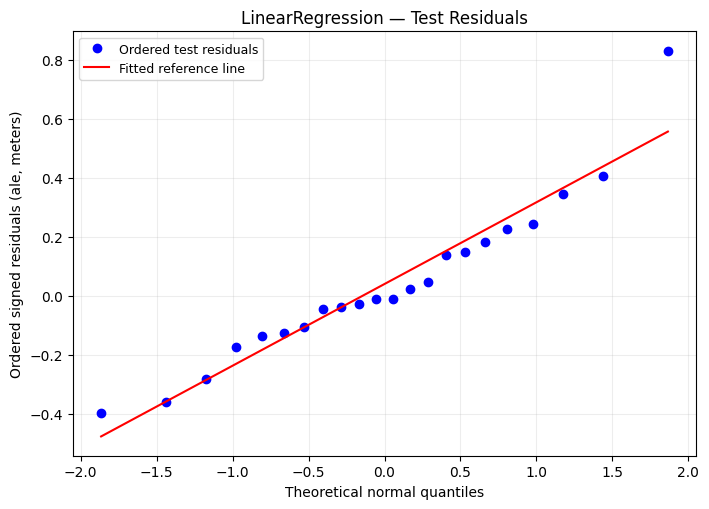

Saved: figures/linear_regression_test_residuals.png


In [6]:
plot_test_residuals("LinearRegression", "linear_regression_test_residuals.png")

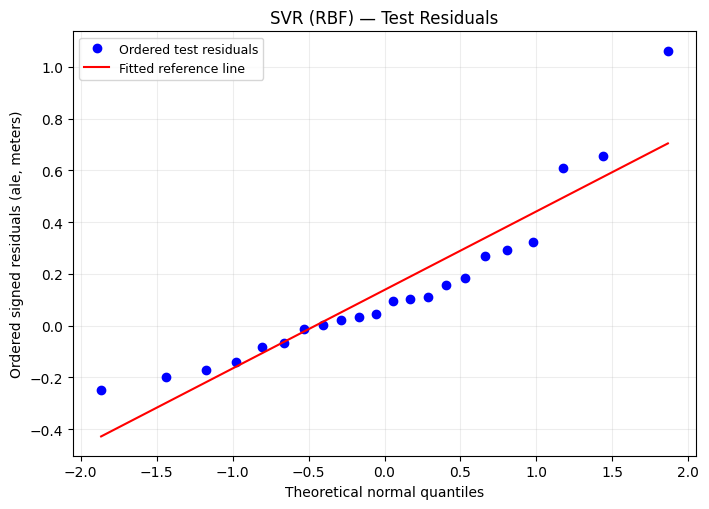

Saved: figures/svr_rbf_test_residuals.png


In [7]:
plot_test_residuals("SVR (RBF)", "svr_rbf_test_residuals.png")

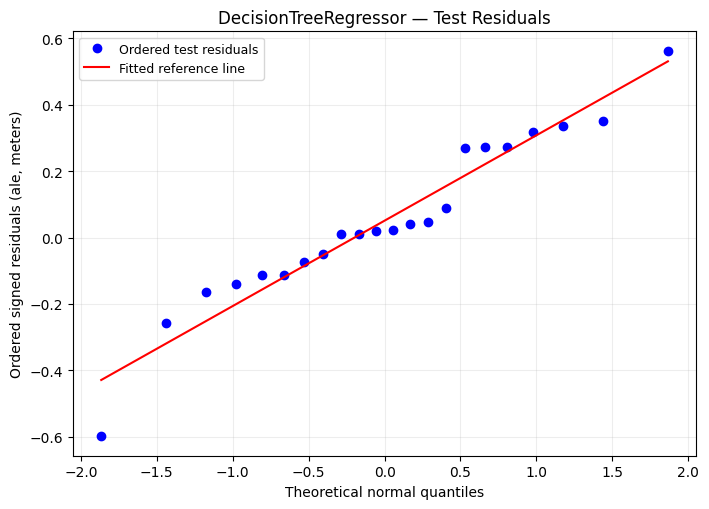

Saved: figures/decision_tree_test_residuals.png


In [8]:
plot_test_residuals("DecisionTreeRegressor", "decision_tree_test_residuals.png")

## Short analysis for the homework answer

I used the real UCI ALE dataset (107 observations) to predict `ale` from `anchor_ratio`, `trans_range`, `node_density`, and `iterations`, excluding `sd_ale`. As fixed implementation choices, I used a single 80/20 split with `random_state=42`, yielding 85 training observations and 22 test observations. I fitted `LinearRegression()`, an RBF SVR with `C=1.0`, `epsilon=0.1`, and `gamma="scale"` in a `StandardScaler` pipeline, and a decision tree with `max_depth=3`, `min_samples_leaf=5`, and `random_state=42`. The scaler was fitted on the training set only. No target transformation or hyperparameter tuning was performed. For every model, I examined **held-out test residuals**, defined as observed minus predicted `ale`, in the original units.

For **linear regression**, most central points are near the reference line, but the largest positive residual lies clearly above it, indicating a right-tail departure. The D'Agostino–Pearson statistic is **7.299712197** and the p-value is **2.599486921e-02**. Since this is below 0.05, I **reject normality at the 5% level**. The test MAE is **0.195393416 meters**.

For **RBF SVR**, the probability plot shows curvature and several large positive residuals in the upper tail, with the largest point well above the reference line. This suggests right skew and is consistent with the normality test: statistic **12.338414588**, p-value **2.092894393e-03**. I **reject normality at the 5% level**. The test MAE is **0.221835613 meters**.

For the **decision tree**, the plot follows the general linear trend but has visible local departures, including a negative extreme below the reference line and a cluster of positive residuals. Its statistic is **1.814247267** and its p-value is **4.036836979e-01**. I **fail to reject normality at the 5% level**. This means the test did not find sufficient evidence against normality in this sample; it does **not** establish that the residual distribution is normal. The test MAE is **0.188095406 meters**.

Thus, linear regression and RBF SVR show evidence of non-normal residuals in this experiment, while the decision tree does not reach the fixed rejection threshold. MAE is reported only as an additional measure of prediction-error magnitude, not as a normality test or a Q4-specified metric. With only 22 held-out residuals per model, the normality assessment has limited power, and the conclusions apply to the current sample and split. No residuals were deleted, transformed, or resampled to obtain a preferred p-value.